In [1]:
# ==========================================
# Import Required Libraries
# ==========================================

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    precision_recall_curve,
    roc_curve
)

from sklearn.preprocessing import MinMaxScaler

from imblearn.over_sampling import SMOTE

pd.set_option('display.max_columns', None)

print("Libraries Imported Successfully")

Libraries Imported Successfully


In [2]:
# ==========================================
# Load Dataset
# ==========================================

df = pd.read_csv("creditcard.csv")

print(df.shape)

df.head()

(284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,0.090794,-0.551600,-0.617801,-0.991390,-0.311169,1.468177,-0.470401,0.207971,0.025791,0.403993,0.251412,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,-0.166974,1.612727,1.065235,0.489095,-0.143772,0.635558,0.463917,-0.114805,-0.183361,-0.145783,-0.069083,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,0.207643,0.624501,0.066084,0.717293,-0.165946,2.345865,-2.890083,1.109969,-0.121359,-2.261857,0.524980,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,-0.054952,-0.226487,0.178228,0.507757,-0.287924,-0.631418,-1.059647,-0.684093,1.965775,-1.232622,-0.208038,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,0.753074,-0.822843,0.538196,1.345852,-1.119670,0.175121,-0.451449,-0.237033,-0.038195,0.803487,0.408542,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [3]:
# ==========================================
# Dataset Information
# ==========================================

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     28

In [4]:
# ==========================================
# Missing Values
# ==========================================

print(df.isnull().sum())

Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       0
V25       0
V26       0
V27       0
V28       0
Amount    0
Class     0
dtype: int64


In [5]:
# ==========================================
# Remove Duplicate Records
# ==========================================

print("Before :",df.shape)

df = df.drop_duplicates()

print("After :",df.shape)

print("Duplicates :",df.duplicated().sum())

Before : (284807, 31)
After : (283726, 31)
Duplicates : 0


In [6]:
# ==========================================
# Class Distribution
# ==========================================

print(df['Class'].value_counts())

print()

print(df['Class'].value_counts(normalize=True)*100)

Class
0    283253
1       473
Name: count, dtype: int64

Class
0    99.83329
1     0.16671
Name: proportion, dtype: float64


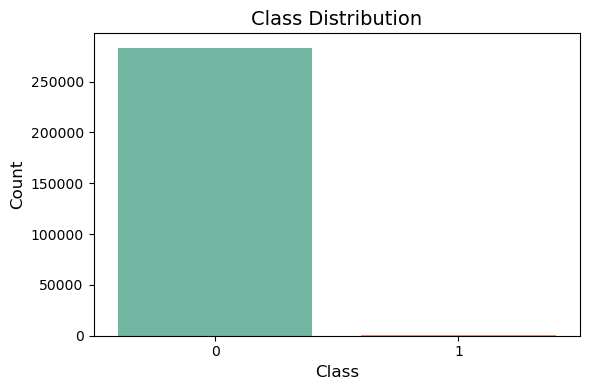

In [7]:
# ==========================================
# Plot Class Distribution
# ==========================================

plt.figure(figsize=(6,4))

sns.countplot(
    x='Class',
    data=df,
    palette='Set2'
)

plt.title("Class Distribution", fontsize=14)
plt.xlabel("Class", fontsize=12)
plt.ylabel("Count", fontsize=12)

plt.tight_layout()

plt.savefig(
    "Class_Distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [8]:
# ==========================================
# Feature Matrix and Target
# ==========================================

X = df.drop(columns=['Class'])

y = df['Class']

print(X.shape)

print(y.shape)

(283726, 30)
(283726,)


In [9]:
# ==========================================
# Train Test Split
# ==========================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(X_train.shape)
print(X_test.shape)

(226980, 30)
(56746, 30)


In [10]:
# ==========================================
# Baseline Random Forest (WITHOUT SMOTE)
# ==========================================

baseline_rf = RandomForestClassifier(
    random_state=42,
    n_jobs=-1
)

baseline_rf.fit(X_train, y_train)

baseline_pred = baseline_rf.predict(X_test)

baseline_prob = baseline_rf.predict_proba(X_test)[:,1]

In [11]:
# ==========================================
# Baseline Model Evaluation
# ==========================================

print("Accuracy :", round(accuracy_score(y_test, baseline_pred),4))
print("Precision :", round(precision_score(y_test, baseline_pred),4))
print("Recall :", round(recall_score(y_test, baseline_pred),4))
print("F1 Score :", round(f1_score(y_test, baseline_pred),4))
print("ROC AUC :", round(roc_auc_score(y_test, baseline_prob),4))

Accuracy : 0.9995
Precision : 0.9718
Recall : 0.7263
F1 Score : 0.8313
ROC AUC : 0.9239


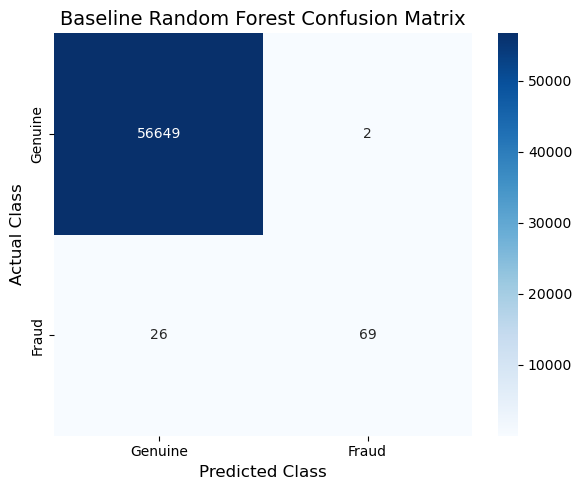

In [12]:
# ==========================================
# Baseline Random Forest Confusion Matrix
# ==========================================

cm = confusion_matrix(y_test, baseline_pred)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    cbar=True,
    xticklabels=['Genuine', 'Fraud'],
    yticklabels=['Genuine', 'Fraud']
)

plt.title("Baseline Random Forest Confusion Matrix", fontsize=14)
plt.xlabel("Predicted Class", fontsize=12)
plt.ylabel("Actual Class", fontsize=12)

plt.tight_layout()

# Save for IEEE Paper
plt.savefig(
    "Baseline_RF_Confusion_Matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [13]:
# ==========================================
# Apply SMOTE
# ==========================================

smote = SMOTE(random_state=42)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train,
    y_train
)

print("Before SMOTE")
print(y_train.value_counts())

print("\nAfter SMOTE")
print(y_train_smote.value_counts())

Before SMOTE
Class
0    226602
1       378
Name: count, dtype: int64

After SMOTE
Class
0    226602
1    226602
Name: count, dtype: int64


In [14]:
# ==========================================
# Random Forest with SMOTE
# ==========================================

rf_smote = RandomForestClassifier(
    random_state=42,
    n_jobs=-1
)

rf_smote.fit(X_train_smote, y_train_smote)

smote_pred = rf_smote.predict(X_test)

smote_prob = rf_smote.predict_proba(X_test)[:,1]

In [15]:
# ==========================================
# SMOTE Model Evaluation
# ==========================================

print("Accuracy :", round(accuracy_score(y_test, smote_pred),4))
print("Precision :", round(precision_score(y_test, smote_pred),4))
print("Recall :", round(recall_score(y_test, smote_pred),4))
print("F1 Score :", round(f1_score(y_test, smote_pred),4))
print("ROC AUC :", round(roc_auc_score(y_test, smote_prob),4))

Accuracy : 0.9995
Precision : 0.8902
Recall : 0.7684
F1 Score : 0.8249
ROC AUC : 0.9609


In [16]:
# ==========================================
# Optimized Random Forest (Fast Version)
# ==========================================

best_rf = RandomForestClassifier(
    n_estimators=200,
    max_depth=20,
    min_samples_split=2,
    min_samples_leaf=1,
    random_state=42,
    n_jobs=-1
)

best_rf.fit(X_train_smote, y_train_smote)

best_pred = best_rf.predict(X_test)

best_prob = best_rf.predict_proba(X_test)[:,1]

In [17]:
print("Accuracy :", round(accuracy_score(y_test,best_pred),4))
print("Precision :", round(precision_score(y_test,best_pred),4))
print("Recall :", round(recall_score(y_test,best_pred),4))
print("F1 :", round(f1_score(y_test,best_pred),4))
print("ROC AUC :", round(roc_auc_score(y_test,best_prob),4))

Accuracy : 0.9995
Precision : 0.881
Recall : 0.7789
F1 : 0.8268
ROC AUC : 0.9554


In [18]:
# ==========================================
# Find Best Threshold
# ==========================================

from sklearn.metrics import precision_recall_curve

precision, recall, thresholds = precision_recall_curve(
    y_test,
    best_prob
)

f1_scores = (2 * precision * recall) / (precision + recall + 1e-10)

best_index = np.argmax(f1_scores)

base_threshold = thresholds[best_index]

print("Best Threshold:", round(base_threshold,4))
print("Best F1:", round(f1_scores[best_index],4))

Best Threshold: 0.4398
Best F1: 0.8333


In [19]:
# ==========================================
# PATF - Create Risk Score
# ==========================================

from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

amount_scaled = scaler.fit_transform(
    X_test[['Amount']]
).flatten()

risk_score = (
    0.8 * best_prob +
    0.2 * amount_scaled
)

risk_df = pd.DataFrame({
    'Probability': best_prob,
    'Amount': X_test['Amount'].values,
    'RiskScore': risk_score
})

risk_df.head()

,Probability,Amount,RiskScore
0,2.691681e-07,11.50,0.000090
1,2.691681e-07,1.94,0.000015
2,1.990868e-02,91.28,0.016638
3,0.000000e+00,228.00,0.001775
4,0.000000e+00,1.41,0.000011


In [20]:
# ==========================================
# Adaptive Thresholds
# ==========================================

q1 = risk_df['RiskScore'].quantile(0.33)
q2 = risk_df['RiskScore'].quantile(0.66)

print("Low Risk Boundary :", round(q1,4))
print("High Risk Boundary :", round(q2,4))

Low Risk Boundary : 0.0001
High Risk Boundary : 0.0007


In [21]:
# ==========================================
# PATF Prediction
# ==========================================

pred_patf = []

for _, row in risk_df.iterrows():

    prob = row['Probability']
    risk = row['RiskScore']

    if risk <= q1:
        threshold = base_threshold + 0.05

    elif risk <= q2:
        threshold = base_threshold

    else:
        threshold = base_threshold - 0.05

    pred_patf.append(
        1 if prob >= threshold else 0
    )

pred_patf = np.array(pred_patf)

print("PATF Predictions Generated Successfully")

PATF Predictions Generated Successfully


In [22]:
# ==========================================
# PATF Evaluation
# ==========================================

print("Accuracy :", round(accuracy_score(y_test,pred_patf),4))
print("Precision :", round(precision_score(y_test,pred_patf),4))
print("Recall :", round(recall_score(y_test,pred_patf),4))
print("F1 Score :", round(f1_score(y_test,pred_patf),4))
print("ROC AUC :", round(roc_auc_score(y_test,pred_patf),4))

Accuracy : 0.9994
Precision : 0.8539
Recall : 0.8
F1 Score : 0.8261
ROC AUC : 0.8999


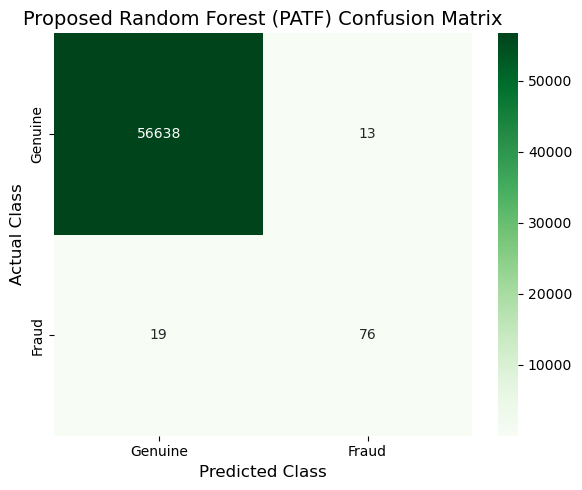

In [23]:
# ==========================================
# PATF Confusion Matrix
# ==========================================

cm = confusion_matrix(y_test, pred_patf)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Greens',
    cbar=True,
    xticklabels=['Genuine', 'Fraud'],
    yticklabels=['Genuine', 'Fraud']
)

plt.title("Proposed Random Forest (PATF) Confusion Matrix", fontsize=14)
plt.xlabel("Predicted Class", fontsize=12)
plt.ylabel("Actual Class", fontsize=12)

plt.tight_layout()

# Save figure for IEEE paper
plt.savefig(
    "PATF_Confusion_Matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

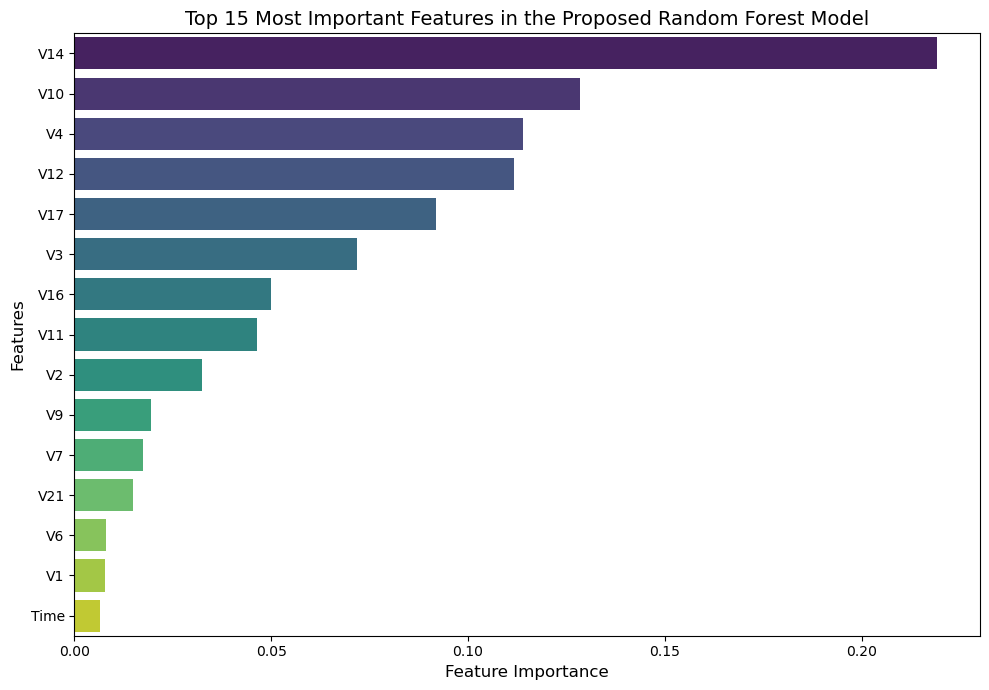

In [24]:
# ==========================================
# Feature Importance
# ==========================================

importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': best_rf.feature_importances_
})

importance = importance.sort_values(
    by='Importance',
    ascending=False
)

plt.figure(figsize=(10,7))

sns.barplot(
    data=importance.head(15),
    x='Importance',
    y='Feature',
    palette='viridis'
)

plt.title(
    "Top 15 Most Important Features in the Proposed Random Forest Model",
    fontsize=14
)

plt.xlabel("Feature Importance", fontsize=12)
plt.ylabel("Features", fontsize=12)

plt.tight_layout()

# Save figure for IEEE Paper
plt.savefig(
    "RF_Feature_Importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [25]:
# ==========================================
# Final Comparison
# ==========================================

comparison = pd.DataFrame({

'Model':[
'Baseline RF',
'SMOTE RF',
'Optimized RF',
'PATF RF'
],

'Accuracy':[
accuracy_score(y_test,baseline_pred),
accuracy_score(y_test,smote_pred),
accuracy_score(y_test,best_pred),
accuracy_score(y_test,pred_patf)
],

'Precision':[
precision_score(y_test,baseline_pred),
precision_score(y_test,smote_pred),
precision_score(y_test,best_pred),
precision_score(y_test,pred_patf)
],

'Recall':[
recall_score(y_test,baseline_pred),
recall_score(y_test,smote_pred),
recall_score(y_test,best_pred),
recall_score(y_test,pred_patf)
],

'F1 Score':[
f1_score(y_test,baseline_pred),
f1_score(y_test,smote_pred),
f1_score(y_test,best_pred),
f1_score(y_test,pred_patf)
],

'ROC AUC':[
roc_auc_score(y_test,baseline_prob),
roc_auc_score(y_test,smote_prob),
roc_auc_score(y_test,best_prob),
roc_auc_score(y_test,best_prob)
]

})

comparison

,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC
0,Baseline RF,0.999507,0.971831,0.726316,0.831325,0.923944
1,SMOTE RF,0.999454,0.890244,0.768421,0.824859,0.960894
2,Optimized RF,0.999454,0.880952,0.778947,0.826816,0.955445
3,PATF RF,0.999436,0.853933,0.800000,0.826087,0.955445


In [26]:
# Example transaction from the test set

sample = X_test.iloc[[10]]

probability = best_rf.predict_proba(sample)[0][1]

prediction = best_rf.predict(sample)[0]

print("Fraud Probability :", round(probability,4))

if prediction==1:
    print("Prediction : Fraud")
else:
    print("Prediction : Genuine")

Fraud Probability : 0.0
Prediction : Genuine
